In [361]:
print('In the name of Allah')

In the name of Allah


In [362]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder,StandardScaler,MinMaxScaler

# Mandatory Problems

1. Diabetes Dataset – Missing Value Imputation & Encoding

Dataset Link:

https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

Use the Pima Indians Diabetes Database dataset.

Tasks:



*   Load the dataset using Pandas.
*   Check missing values using isnull().sum().
*   Replace invalid 0 values in columns like Glucose, BloodPressure, and BMI with NaN.
*   Apply :
      *   Necessary Imputation ( Must be done with the proper one )
*   Create a categorical column:
      *   Age_Group
            *   Young (<30)
            *   Adult (30–50)
            *   Senior (>50)

Apply Encoding on Age_Group. Choose the proper encoding technique and explain why it is the best one.


In [363]:
df = pd.read_csv('diabetes.csv')

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [364]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [365]:
( df == 0 ).sum()

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [366]:
# df['Glucose', 'BloodPressure', 'BMI'] = df['Glucose', 'BloodPressure', 'BMI'].replace(0, np.nan)

df = df.replace(0, np.nan)

df.isnull().sum()

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [367]:
df.info()
# Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, Outcome

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               657 non-null    float64
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   268 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 54.1 KB


In [368]:
# Train Test Split

X = df.drop(['Outcome'], axis = 1) # Feature

y = df['Outcome'] # Target Column

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [369]:
X_train
display(y_train)

,Outcome
60,NaN
618,1.0
346,NaN
294,NaN
231,1.0
...,...
71,NaN
106,NaN
270,1.0
435,1.0


In [370]:
X_test

display(y_test)

,Outcome
668,NaN
324,NaN
624,NaN
690,NaN
473,NaN
...,...
355,1.0
534,NaN
344,NaN
296,1.0


In [371]:
X_train.isnull().sum()

,0
Pregnancies,91
Glucose,5
BloodPressure,24
SkinThickness,176
Insulin,290
BMI,7
DiabetesPedigreeFunction,0
Age,0


In [372]:
X_test.isnull().sum()

,0
Pregnancies,20
Glucose,0
BloodPressure,11
SkinThickness,51
Insulin,84
BMI,4
DiabetesPedigreeFunction,0
Age,0


In [373]:
cols_missing = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

In [374]:
df[cols_missing].skew()

,0
Pregnancies,0.885535
Glucose,0.530989
BloodPressure,0.134153
SkinThickness,0.690619
Insulin,2.166464
BMI,0.593970


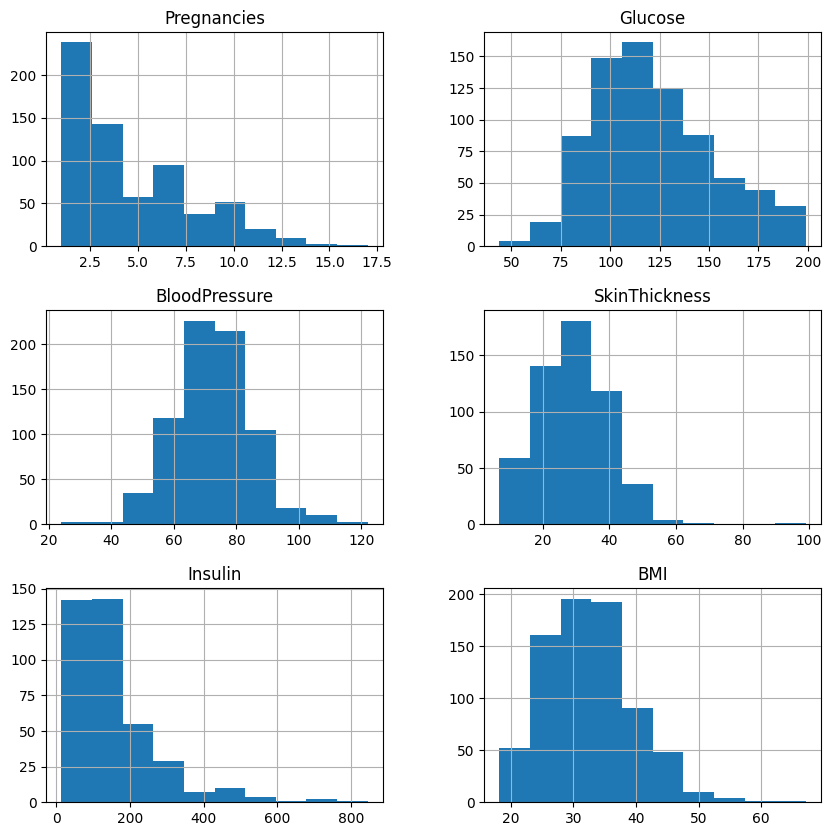

In [375]:
df[cols_missing].hist(figsize=(10,10))

plt.show()

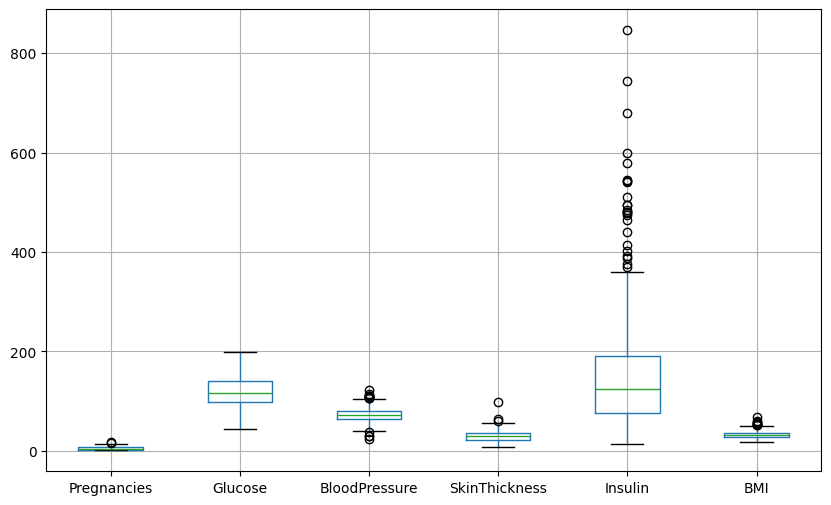

In [376]:
df[cols_missing].boxplot(figsize=(10,6))

plt.show()

In [377]:
df[cols_missing].describe() # If max is far than mean, we will choose median

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI
count,657.000000,763.000000,733.000000,541.000000,394.000000,757.000000
mean,4.494673,121.686763,72.405184,29.153420,155.548223,32.457464
std,3.217291,30.535641,12.382158,10.476982,118.775855,6.924988
min,1.000000,44.000000,24.000000,7.000000,14.000000,18.200000
25%,2.000000,99.000000,64.000000,22.000000,76.250000,27.500000
50%,4.000000,117.000000,72.000000,29.000000,125.000000,32.300000
75%,7.000000,141.000000,80.000000,36.000000,190.000000,36.600000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000


In [378]:
# We will use Median imputation

imputer_transformer = ColumnTransformer(
    transformers = [
    ( 'all', SimpleImputer( strategy = 'median' ), ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

imputer_transformer.set_output( transform = 'pandas' )

imputer_transformer.fit(X_train)

X_train = imputer_transformer.transform(X_train)

X_test = imputer_transformer.transform(X_test)

In [379]:
X_train.isnull().sum()

X_train.sample(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
230,4.0,142.0,86.0,28.5,120.0,44.0,0.645,22
705,6.0,80.0,80.0,36.0,120.0,39.8,0.177,28
752,3.0,108.0,62.0,24.0,120.0,26.0,0.223,25
357,13.0,129.0,72.0,30.0,120.0,39.9,0.569,44
593,2.0,82.0,52.0,22.0,115.0,28.5,1.699,25


In [380]:
X_test.isnull().sum()

X_test.sample(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
617,2.0,68.0,62.0,13.0,15.0,20.1,0.257,23
193,11.0,135.0,72.0,28.5,120.0,52.3,0.578,40
97,1.0,71.0,48.0,18.0,76.0,20.4,0.323,22
534,1.0,77.0,56.0,30.0,56.0,33.3,1.251,24
227,3.0,162.0,52.0,38.0,120.0,37.2,0.652,24


In [381]:
X_train.info()

X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 614 entries, 60 to 102
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               614 non-null    float64
 1   Glucose                   614 non-null    float64
 2   BloodPressure             614 non-null    float64
 3   SkinThickness             614 non-null    float64
 4   Insulin                   614 non-null    float64
 5   BMI                       614 non-null    float64
 6   DiabetesPedigreeFunction  614 non-null    float64
 7   Age                       614 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 43.2 KB
<class 'pandas.core.frame.DataFrame'>
Index: 154 entries, 668 to 462
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               154 non-null    float64
 1   Glucose                   15

<Axes: xlabel='Age', ylabel='Count'>

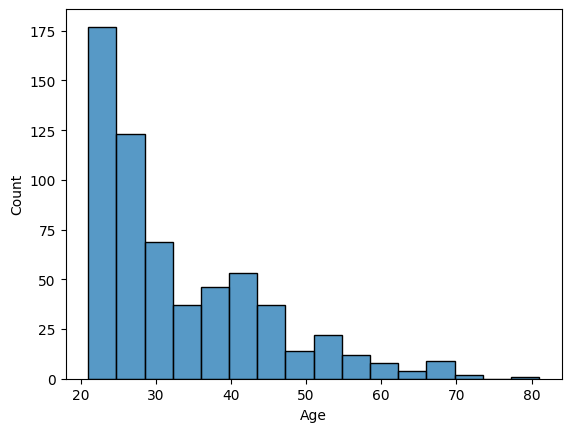

In [382]:
sns.histplot( data = X_train, x = X_train['Age'] )

In [383]:
def age_group(age) :
  if age < 30 :
    return 'Young'
  elif 30 <= age <= 50 :
    return 'Adult'
  else :
    return 'Senior'

X_train['Age_Group'] = X_train['Age'].apply(age_group)

X_test['Age_Group'] = X_test['Age'].apply(age_group)

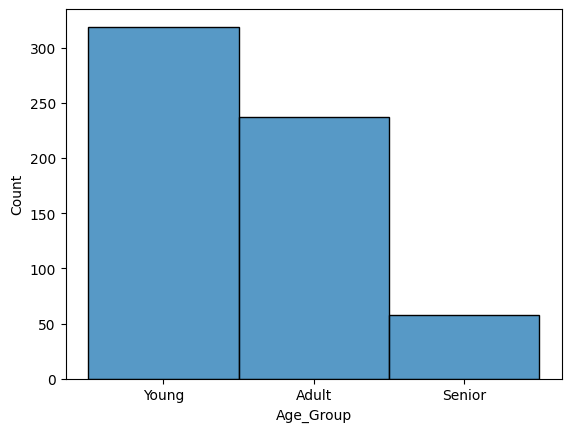

<Axes: xlabel='Age_Group', ylabel='Count'>

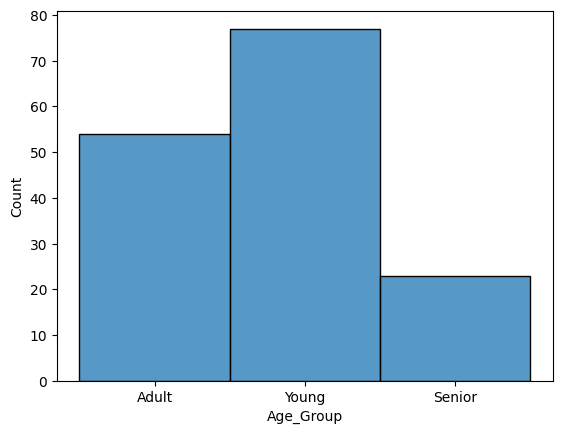

In [384]:
sns.histplot( data = X_train, x = X_train['Age_Group'] )

plt.show()

sns.histplot( data = X_test, x = X_test['Age_Group'] )

In [385]:
X_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Age_Group
60,2.0,84.0,72.0,28.5,120.0,32.0,0.304,21,Young
618,9.0,112.0,82.0,24.0,120.0,28.2,1.282,50,Adult
346,1.0,139.0,46.0,19.0,83.0,28.7,0.654,22,Young
294,4.0,161.0,50.0,28.5,120.0,21.9,0.254,65,Senior
231,6.0,134.0,80.0,37.0,370.0,46.2,0.238,46,Adult
...,...,...,...,...,...,...,...,...,...
71,5.0,139.0,64.0,35.0,140.0,28.6,0.411,26,Young
106,1.0,96.0,122.0,28.5,120.0,22.4,0.207,27,Young
270,10.0,101.0,86.0,37.0,120.0,45.6,1.136,38,Adult
435,4.0,141.0,72.0,28.5,120.0,42.4,0.205,29,Young


In [386]:
from sklearn.preprocessing import OrdinalEncoder

age_encoder = OrdinalEncoder(categories = [['Young', 'Adult', 'Senior']])

age_encoder.fit(X_train[['Age_Group']])

# Transform

X_train['encoded_age'] = age_encoder.transform(X_train[['Age_Group']]).ravel()

X_test['encoded_age'] = age_encoder.transform(X_test[['Age_Group']]).ravel()

X_train.sample(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Age_Group,encoded_age
288,4.0,96.0,56.0,17.0,49.0,20.8,0.340,26,Young,0.0
70,2.0,100.0,66.0,20.0,90.0,32.9,0.867,28,Young,0.0
574,1.0,143.0,86.0,30.0,330.0,30.1,0.892,23,Young,0.0
376,4.0,98.0,82.0,15.0,84.0,25.2,0.299,22,Young,0.0
153,1.0,153.0,82.0,42.0,485.0,40.6,0.687,23,Young,0.0
502,6.0,118.0,68.0,41.0,120.0,39.0,0.727,41,Adult,1.0
162,4.0,114.0,80.0,34.0,285.0,44.2,0.167,27,Young,0.0
53,8.0,176.0,90.0,34.0,300.0,33.7,0.467,58,Senior,2.0
21,8.0,99.0,84.0,28.5,120.0,35.4,0.388,50,Adult,1.0
268,4.0,102.0,52.0,28.5,120.0,25.1,0.078,21,Young,0.0


In [387]:
X_test.sample(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Age_Group,encoded_age
213,4.0,140.0,65.0,26.0,130.0,42.6,0.431,24,Young,0.0
513,2.0,91.0,62.0,28.5,120.0,27.3,0.525,22,Young,0.0
192,7.0,159.0,66.0,28.5,120.0,30.4,0.383,36,Adult,1.0
265,5.0,96.0,74.0,18.0,67.0,33.6,0.997,43,Adult,1.0
133,8.0,84.0,74.0,31.0,120.0,38.3,0.457,39,Adult,1.0
690,8.0,107.0,80.0,28.5,120.0,24.6,0.856,34,Adult,1.0
212,7.0,179.0,95.0,31.0,120.0,34.2,0.164,60,Senior,2.0
148,5.0,147.0,78.0,28.5,120.0,33.7,0.218,65,Senior,2.0
97,1.0,71.0,48.0,18.0,76.0,20.4,0.323,22,Young,0.0
581,6.0,109.0,60.0,27.0,120.0,25.0,0.206,27,Young,0.0


Chosen Encoding technique is Ordinal Encoding.
The Ordinal encoding is best choice because :

*   The Age_Group feature has a natural order: Young < Adult < Senior

*   Ordinal Encoding preserves this ranking relationship between categories

*   It is more meaningful for machine learning models compared to Label Encoding or One-Hot Encoding

*   One-Hot Encoding ignores order and increases dimensionality unnecessarily

# 2. Heart Disease Dataset – One Hot Encoding

## Dataset Link

Heart Disease UCI Dataset:  
https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset

---

## Tasks

1. Load the dataset using Pandas.  

2. Identify the categorical columns in the dataset.  

3. Apply One Hot Encoding on:
   - cp (Chest Pain Type)
   - thal

4. Compare the dataframe shape before and after encoding.

In [388]:
df = pd.read_csv('heart.csv')

df
# sex, cp, fbs, restecg, exang, slope, ca, thal, target

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [389]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


## Identified Categorical Columns

The following columns in the Heart Disease dataset are categorical in nature:

- sex
- cp
- fbs
- restecg
- exang
- slope
- ca
- thal
- target

Although these columns contain numeric values, they represent categories or classes rather than continuous numerical measurements.

In [390]:
# Train Test Split

X = df.drop(['target'], axis = 1) # Feature

y = df['target']

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42 )

In [391]:
X_train

display(y_train)

,target
835,0
137,1
534,1
495,1
244,1
...,...
700,1
71,0
106,0
270,1


In [392]:
X_test

display(y_test)

,target
527,1
359,1
447,0
31,1
621,0
...,...
832,1
796,1
644,1
404,0


In [393]:
print(f'Shape of X_train : {X_train.shape}')
print(f'Shape of X_test : {X_test.shape}')

Shape of X_train : (820, 13)
Shape of X_test : (205, 13)


In [394]:
# Applying OneHot Encoder

from sklearn.preprocessing import OneHotEncoder

cp_ohe = OneHotEncoder( sparse_output = False ).set_output(transform = 'pandas')

cp_ohe.fit(X_train[['cp']])

encoded_df = cp_ohe.transform(X_train[['cp']])

X_train = pd.concat([X_train, encoded_df], axis = 1)

X_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,cp_0,cp_1,cp_2,cp_3
835,49,1,2,118,149,0,0,126,0,0.8,2,3,2,0.0,0.0,1.0,0.0
137,64,0,0,180,325,0,1,154,1,0.0,2,0,2,1.0,0.0,0.0,0.0
534,54,0,2,108,267,0,0,167,0,0.0,2,0,2,0.0,0.0,1.0,0.0
495,59,1,0,135,234,0,1,161,0,0.5,1,0,3,1.0,0.0,0.0,0.0
244,51,1,2,125,245,1,0,166,0,2.4,1,0,2,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,41,1,2,130,214,0,0,168,0,2.0,1,0,2,0.0,0.0,1.0,0.0
71,61,1,0,140,207,0,0,138,1,1.9,2,1,3,1.0,0.0,0.0,0.0
106,51,1,0,140,299,0,1,173,1,1.6,2,0,3,1.0,0.0,0.0,0.0
270,43,1,0,110,211,0,1,161,0,0.0,2,0,3,1.0,0.0,0.0,0.0


In [395]:
encoded_df = cp_ohe.transform(X_test[['cp']])

X_test = pd.concat([X_test, encoded_df], axis = 1)

In [396]:
X_test.sample(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,cp_0,cp_1,cp_2,cp_3
305,62,1,0,120,267,0,1,99,1,1.8,1,2,3,1.0,0.0,0.0,0.0
334,60,1,0,130,206,0,0,132,1,2.4,1,2,3,1.0,0.0,0.0,0.0
310,61,1,0,120,260,0,1,140,1,3.6,1,1,3,1.0,0.0,0.0,0.0
715,70,1,1,156,245,0,0,143,0,0.0,2,0,2,0.0,1.0,0.0,0.0
644,44,1,2,120,226,0,1,169,0,0.0,2,0,2,0.0,0.0,1.0,0.0
832,68,1,2,118,277,0,1,151,0,1.0,2,1,3,0.0,0.0,1.0,0.0
218,46,1,0,140,311,0,1,120,1,1.8,1,2,3,1.0,0.0,0.0,0.0
688,56,0,0,200,288,1,0,133,1,4.0,0,2,3,1.0,0.0,0.0,0.0
822,60,1,0,130,253,0,1,144,1,1.4,2,1,3,1.0,0.0,0.0,0.0
670,61,0,0,130,330,0,0,169,0,0.0,2,0,2,1.0,0.0,0.0,0.0


In [397]:
print(f'Shape of X_train : {X_train.shape}')
print(f'Shape of X_test : {X_test.shape}')

Shape of X_train : (820, 17)
Shape of X_test : (205, 17)


In [398]:
thal_ohe = OneHotEncoder(sparse_output = False).set_output(transform = 'pandas')

thal_ohe.fit( X_train[['thal']] )

encoed_df_thal = thal_ohe.transform(X_train[['thal']])

X_train = pd.concat([X_train, encoed_df_thal], axis = 1)

X_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,ca,thal,cp_0,cp_1,cp_2,cp_3,thal_0,thal_1,thal_2,thal_3
835,49,1,2,118,149,0,0,126,0,0.8,...,3,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
137,64,0,0,180,325,0,1,154,1,0.0,...,0,2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
534,54,0,2,108,267,0,0,167,0,0.0,...,0,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
495,59,1,0,135,234,0,1,161,0,0.5,...,0,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
244,51,1,2,125,245,1,0,166,0,2.4,...,0,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,41,1,2,130,214,0,0,168,0,2.0,...,0,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
71,61,1,0,140,207,0,0,138,1,1.9,...,1,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
106,51,1,0,140,299,0,1,173,1,1.6,...,0,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
270,43,1,0,110,211,0,1,161,0,0.0,...,0,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [399]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 820 entries, 835 to 860
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       820 non-null    int64  
 1   sex       820 non-null    int64  
 2   cp        820 non-null    int64  
 3   trestbps  820 non-null    int64  
 4   chol      820 non-null    int64  
 5   fbs       820 non-null    int64  
 6   restecg   820 non-null    int64  
 7   thalach   820 non-null    int64  
 8   exang     820 non-null    int64  
 9   oldpeak   820 non-null    float64
 10  slope     820 non-null    int64  
 11  ca        820 non-null    int64  
 12  thal      820 non-null    int64  
 13  cp_0      820 non-null    float64
 14  cp_1      820 non-null    float64
 15  cp_2      820 non-null    float64
 16  cp_3      820 non-null    float64
 17  thal_0    820 non-null    float64
 18  thal_1    820 non-null    float64
 19  thal_2    820 non-null    float64
 20  thal_3    820 non-null    float64
d

In [400]:
encoed_df_thal = thal_ohe.transform(X_test[['thal']])

X_test = pd.concat([X_test, encoed_df_thal], axis = 1)

In [401]:
X_test.sample(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,ca,thal,cp_0,cp_1,cp_2,cp_3,thal_0,thal_1,thal_2,thal_3
277,44,1,1,130,219,0,0,188,0,0.0,...,0,2,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
139,41,1,1,110,235,0,1,153,0,0.0,...,0,2,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
265,45,1,0,104,208,0,0,148,1,3.0,...,0,2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
753,65,1,0,120,177,0,1,140,0,0.4,...,0,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
857,43,1,0,115,303,0,1,181,0,1.2,...,0,2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
359,53,0,2,128,216,0,0,115,0,0.0,...,0,0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
973,51,1,2,125,245,1,0,166,0,2.4,...,0,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
525,51,0,2,130,256,0,0,149,0,0.5,...,0,2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
67,42,1,0,136,315,0,1,125,1,1.8,...,0,1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
893,52,1,0,128,204,1,1,156,1,1.0,...,0,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [402]:
print(f'Shape of X_train : {X_train.shape}')
print(f'Shape of X_test : {X_test.shape}')

Shape of X_train : (820, 21)
Shape of X_test : (205, 21)


## 3. Tips Dataset – Label Encoding

### Dataset
Seaborn Tips Dataset

https://github.com/mwaskom/seaborn-data/blob/master/tips.csv?utm_source=chatgpt.com

### Tasks
- Load dataset using Seaborn.
- Apply encoding on:
  - sex  
  - smoker  
- Create a new feature:
  - tip_category
    - Low (< 3)
    - Medium (3–6)
    - High (> 6)
- Encode `tip_category`
- Choose the proper encoding technique and explain why it is the best one.

In [403]:
df = pd.read_csv('tips.csv')

df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [404]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [405]:
X = df.drop(['tip'], axis = 1) # Feature

X

y = df['tip'] # Target

y

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42 )

In [406]:
X_train.isnull().sum()

,0
total_bill,0
sex,0
smoker,0
day,0
time,0
size,0


In [407]:
y_train.isnull().sum()

np.int64(0)

In [408]:
from sklearn.preprocessing import OneHotEncoder

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'sex&smoker', OneHotEncoder(sparse_output = False, drop = 'first'), ['sex', 'smoker'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(X_train)

X_train = encoder_scaler.transform(X_train)

X_test = encoder_scaler.transform(X_test)

In [409]:
X_train
X_test

y_train
y_test

,tip
24,3.18
6,2.00
153,2.00
211,5.16
198,2.00
176,2.00
192,2.56
124,2.52
9,3.23
101,3.00


In [410]:
def categorize_tip( tip ) :
  if tip < 3 :
    return 'Low'
  elif 3 <= tip <= 6 :
    return 'Medium'
  else :
    return 'High'

y_train = y_train.to_frame()  # Convert Series → DataFrame
y_test  = y_test.to_frame()


y_train['tip_category'] = y_train['tip'].apply(categorize_tip)

y_test['tip_category'] = y_test['tip'].apply(categorize_tip)

<Axes: xlabel='tip_category', ylabel='Count'>

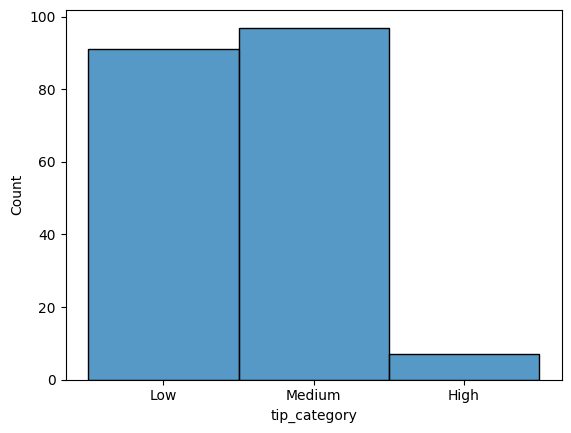

In [411]:
sns.histplot(data = y_train, x = 'tip_category')

## Choosing the Proper Encoding Technique for `tip_category`

For `tip_category`, we use **Ordinal Encoding**.

The reason is simple — `tip_category` is not just a label, it has a
natural order to it. Low is less than Medium, and Medium is less than
High. This kind of feature is called an **ordinal feature**, meaning
the sequence actually matters.

| Category | Encoded Value |
|----------|--------------|
| Low      | 0            |
| Medium   | 1            |
| High     | 2            |

If we used **One-Hot Encoding**, it would treat Low, Medium and High
as completely unrelated categories — which is wrong, because we know
High is greater than Medium and Medium is greater than Low.

If we used **Label Encoding**, it assigns numbers randomly without
any guaranteed order, which could mislead the model.

That is why **Ordinal Encoding is the best choice here** — it
preserves the natural rank of the categories and gives the model
meaningful numerical information to learn from.

In [412]:
from sklearn.preprocessing import OrdinalEncoder

tip_category_encoder = OrdinalEncoder( categories = [['Low', 'Medium', 'High']] )

tip_category_encoder.fit(y_train[['tip_category']])

y_train['tip_category'] = tip_category_encoder.transform(y_train[['tip_category']]).ravel()

y_test['tip_category'] = tip_category_encoder.transform(y_test[['tip_category']]).ravel()

In [413]:
y_train.sample(10)

,tip,tip_category
158,2.61,0.0
228,2.72,0.0
57,1.50,0.0
225,2.50,0.0
237,1.17,0.0
220,2.20,0.0
217,1.50,0.0
188,3.50,1.0
14,3.02,1.0
103,3.48,1.0


## 4. Car Price Dataset – Train/Test Encoding Pipeline

### Dataset
Car Price Prediction Dataset from Kaggle.

https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?utm_source=chatgpt.com

---

### Tasks

**1. Split the dataset into train and test sets first.**

**2. Apply the following encodings:**
- **Ordinal Encoding** on fuel type (Petrol, Diesel, CNG)
- **One Hot Encoding** on transmission type

**3. Handle unknown categories in test data properly.**

**4. Concatenate encoded columns with original dataframe.**

**5. Drop original categorical columns.**

In [414]:
df = pd.read_csv('CarPrice_Assignment.csv')

df

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0


In [415]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [416]:
X = df.drop(['price'], axis = 1)
X

y = df['price']
y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

<Axes: xlabel='fueltype', ylabel='Count'>

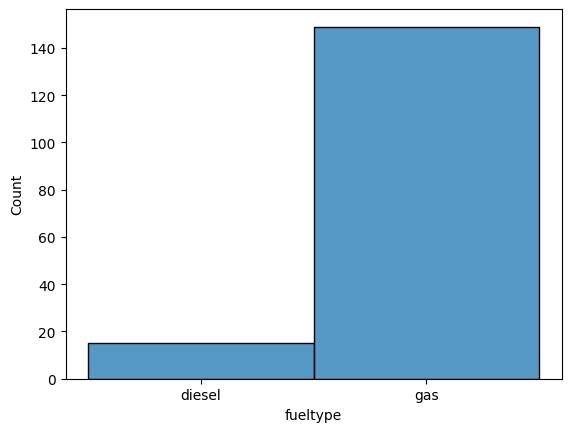

In [417]:
sns.histplot(data = X_train, x = X_train['fueltype'])

In [418]:
# Ordinal Encoding
from sklearn.preprocessing import OrdinalEncoder

fuel_encoder = OrdinalEncoder(categories = [['gas', 'diesel']])

fuel_encoder.fit(X_train[['fueltype']])

X_train['encoded_fuel'] = fuel_encoder.transform(X_train[['fueltype']]).ravel()

X_test['encoded_fuel'] = fuel_encoder.transform(X_test[['fueltype']]).ravel()


In [419]:
# One Hot Encoding
from sklearn.preprocessing import OneHotEncoder

drivewheel_ohe = OneHotEncoder(sparse_output = False).set_output(transform = 'pandas')

drivewheel_ohe.fit(X_train[['drivewheel']])

encoded_df = drivewheel_ohe.transform(X_train[['drivewheel']])

X_train = pd.concat([X_train, encoded_df], axis = 1)

X_train

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,encoded_fuel,drivewheel_4wd,drivewheel_fwd,drivewheel_rwd
66,67,0,mazda rx-7 gs,diesel,std,four,sedan,rwd,front,104.9,...,3.64,22.0,72,4200,31,39,1.0,0.0,0.0,1.0
111,112,0,peugeot 504,gas,std,four,sedan,rwd,front,107.9,...,2.19,8.4,95,5000,19,24,0.0,0.0,0.0,1.0
153,154,0,toyota corona hardtop,gas,std,four,wagon,fwd,front,95.7,...,3.03,9.0,62,4800,31,37,0.0,0.0,1.0,0.0
96,97,1,nissan latio,gas,std,four,sedan,fwd,front,94.5,...,3.29,9.4,69,5200,31,37,0.0,0.0,1.0,0.0
38,39,0,honda civic 1300,gas,std,two,hatchback,fwd,front,96.5,...,3.58,9.0,86,5800,27,33,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,107,1,nissan clipper,gas,std,two,hatchback,rwd,front,99.2,...,3.27,9.0,160,5200,19,25,0.0,0.0,0.0,1.0
14,15,1,bmw z4,gas,std,four,sedan,rwd,front,103.5,...,3.19,9.0,121,4250,20,25,0.0,0.0,0.0,1.0
92,93,1,nissan latio,gas,std,four,sedan,fwd,front,94.5,...,3.29,9.4,69,5200,31,37,0.0,0.0,1.0,0.0
179,180,3,toyota corona,gas,std,two,hatchback,rwd,front,102.9,...,3.35,9.3,161,5200,19,24,0.0,0.0,0.0,1.0


In [420]:
encoded_df = drivewheel_ohe.transform(X_test[['drivewheel']])

X_test = pd.concat([X_test, encoded_df], axis = 1)

X_test

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,encoded_fuel,drivewheel_4wd,drivewheel_fwd,drivewheel_rwd
15,16,0,bmw x4,gas,std,four,sedan,rwd,front,103.5,...,3.390,8.00,182,5400,16,22,0.0,0.0,0.0,1.0
9,10,0,audi 5000s (diesel),gas,turbo,two,hatchback,4wd,front,99.5,...,3.400,7.00,160,5500,16,22,0.0,1.0,0.0,0.0
100,101,0,nissan nv200,gas,std,four,sedan,fwd,front,97.2,...,3.470,8.50,97,5200,27,34,0.0,0.0,1.0,0.0
132,133,3,saab 99e,gas,std,two,hatchback,fwd,front,99.1,...,3.070,9.31,110,5250,21,28,0.0,0.0,1.0,0.0
68,69,-1,buick century luxus (sw),diesel,turbo,four,wagon,rwd,front,110.0,...,3.640,21.50,123,4350,22,25,1.0,0.0,0.0,1.0
95,96,1,nissan juke,gas,std,two,hatchback,fwd,front,94.5,...,3.290,9.40,69,5200,31,37,0.0,0.0,1.0,0.0
159,160,0,toyota corolla,diesel,std,four,hatchback,fwd,front,95.7,...,3.350,22.50,56,4500,38,47,1.0,0.0,1.0,0.0
162,163,0,toyota mark ii,gas,std,four,sedan,fwd,front,95.7,...,3.030,9.00,70,4800,28,34,0.0,0.0,1.0,0.0
147,148,0,subaru tribeca,gas,std,four,wagon,fwd,front,97.0,...,2.640,9.00,94,5200,25,31,0.0,0.0,1.0,0.0
182,183,2,vokswagen rabbit,diesel,std,two,sedan,fwd,front,97.3,...,3.400,23.00,52,4800,37,46,1.0,0.0,1.0,0.0


In [421]:
print(X_train.shape)
print(X_test.shape)

(164, 29)
(41, 29)


In [422]:
X_train.drop('drivewheel', axis = 1, inplace = True)

In [423]:
X_test.drop('drivewheel', axis = 1, inplace = True)

In [424]:
X_train.shape

(164, 28)

In [425]:
X_test.shape

(41, 28)

# Optional Problems

## 5. Heart Disease Dataset – Preprocessing Pipeline

### Dataset
Heart Disease UCI Dataset from Kaggle.

https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset?utm_source=chatgpt.com
---

### Tasks

**1. Preprocessing includes:**
- Missing value imputation
- Outlier detection using IQR
- One Hot Encoding
- Ordinal Encoding

**2. Use `ColumnTransformer` to apply all transformations.**

**3. Transform both training and testing datasets properly.**

**4. Display final transformed feature matrix shape.**

In [426]:
df = pd.read_csv('heart_01.csv')

df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [427]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [428]:
df.sample(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
416,54,1,2,125,273,0,0,152,0,0.5,0,1,2,1
325,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
290,52,1,2,138,223,0,1,169,0,0.0,2,4,2,1
406,58,1,2,140,211,1,0,165,0,0.0,2,0,2,1
340,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
327,57,1,0,150,276,0,0,112,1,0.6,1,1,1,0
541,44,1,2,140,235,0,0,180,0,0.0,2,0,2,1
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0
916,65,1,0,135,254,0,0,127,0,2.8,1,1,3,0
801,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1


In [429]:
( df == 0 ).sum()

,0
age,0
sex,312
cp,497
trestbps,0
chol,0
fbs,872
restecg,497
thalach,0
exang,680
oldpeak,329


In [430]:
df = df.replace(0, np.nan)

df.isnull().sum()

,0
age,0
sex,312
cp,497
trestbps,0
chol,0
fbs,872
restecg,497
thalach,0
exang,680
oldpeak,329


In [431]:
X = df.drop('target', axis = 1)

y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [432]:
X_train
display(y_train)

,target
835,NaN
137,1.0
534,1.0
495,1.0
244,1.0
...,...
700,1.0
71,NaN
106,NaN
270,1.0


In [433]:
X_test
display(y_test)

,target
527,1.0
359,1.0
447,NaN
31,1.0
621,NaN
...,...
832,1.0
796,1.0
644,1.0
404,NaN


In [434]:
X_train.isnull().sum()

,0
age,0
sex,246
cp,398
trestbps,0
chol,0
fbs,700
restecg,406
thalach,0
exang,537
oldpeak,268


In [435]:
X_train['thal'].unique() # sex, cp, fbs, restecg, exang, slope, ca, thal

array([ 2.,  3.,  1., nan])

In [436]:
sex_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

sex_imputer.fit(X_train[['sex']])

# transform

X_train['sex'] = sex_imputer.transform(X_train[['sex']]).ravel()
X_test['sex'] = sex_imputer.transform(X_test[['sex']]).ravel()

In [437]:
X_train['sex'].isnull().sum()

X_test['sex'].isnull().sum()

np.int64(0)

In [438]:
cp_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

cp_imputer.fit(X_train[['cp']])

# transform

X_train['cp'] = cp_imputer.transform(X_train[['cp']]).ravel()

X_test['cp'] = cp_imputer.transform(X_test[['cp']]).ravel()

In [439]:
X_train['cp'].isnull().sum()
X_test['cp'].isnull().sum()

np.int64(0)

In [440]:
fbs_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

fbs_imputer.fit(X_train[['fbs']])

# transform

X_train['fbs'] = fbs_imputer.transform(X_train[['fbs']])
X_test['fbs'] = fbs_imputer.transform(X_test[['fbs']])

In [441]:
X_train['fbs'].isnull().sum()
X_test['fbs'].isnull().sum()

np.int64(0)

In [442]:
restecg_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

restecg_imputer.fit(X_train[['restecg']])

# tranform

X_train['restecg'] = restecg_imputer.transform(X_train[['restecg']])
X_test['restecg'] = restecg_imputer.transform(X_test[['restecg']])

In [443]:
X_train['restecg'].isnull().sum()
X_test['restecg'].isnull().sum()

np.int64(0)

In [444]:
exang_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

exang_imputer.fit(X_train[['exang']])

# transform

X_train['exang'] = exang_imputer.transform(X_train[['exang']])
X_test['exang'] = exang_imputer.transform(X_test[['exang']])

In [445]:
X_train['exang'].isnull().sum()
X_test['exang'].isnull().sum()

np.int64(0)

In [446]:
slope_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

slope_imputer.fit(X_train[['slope']])

# transform

X_train['slope'] = slope_imputer.transform(X_train[['slope']])
X_test['slope'] = slope_imputer.transform(X_test[['slope']])

In [447]:
X_train['slope'].isnull().sum()
X_test['slope'].isnull().sum()

np.int64(0)

In [448]:
ca_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

ca_imputer.fit(X_train[['ca']])

# transform

X_train['ca'] = ca_imputer.transform(X_train[['ca']])
X_test['ca'] = ca_imputer.transform(X_test[['ca']])

In [449]:
X_train['ca'].isnull().sum()
X_test['ca'].isnull().sum()

np.int64(0)

In [450]:
thal_imputer = SimpleImputer( missing_values = np.nan, strategy = 'most_frequent' )

thal_imputer.fit(X_train[['thal']])

# transform

X_train['thal'] = thal_imputer.transform(X_train[['thal']])
X_test['thal'] = thal_imputer.transform(X_test[['thal']])

In [451]:
X_train.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,268


In [452]:
X_test.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,61


In [453]:
# mean imputing

oldpeak_mean = X_train['oldpeak'].mean()

X_train['oldpeak_mean_imputor'] = X_train['oldpeak'].fillna(oldpeak_mean)

X_test['oldpeak_mean_imputor'] = X_test['oldpeak'].fillna(oldpeak_mean)

X_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,oldpeak_mean_imputor
835,49,1.0,2.0,118,149,1.0,1.0,126,1.0,0.8,2.0,3.0,2.0,0.80000
137,64,1.0,2.0,180,325,1.0,1.0,154,1.0,NaN,2.0,1.0,2.0,1.54529
534,54,1.0,2.0,108,267,1.0,1.0,167,1.0,NaN,2.0,1.0,2.0,1.54529
495,59,1.0,2.0,135,234,1.0,1.0,161,1.0,0.5,1.0,1.0,3.0,0.50000
244,51,1.0,2.0,125,245,1.0,1.0,166,1.0,2.4,1.0,1.0,2.0,2.40000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,41,1.0,2.0,130,214,1.0,1.0,168,1.0,2.0,1.0,1.0,2.0,2.00000
71,61,1.0,2.0,140,207,1.0,1.0,138,1.0,1.9,2.0,1.0,3.0,1.90000
106,51,1.0,2.0,140,299,1.0,1.0,173,1.0,1.6,2.0,1.0,3.0,1.60000
270,43,1.0,2.0,110,211,1.0,1.0,161,1.0,NaN,2.0,1.0,3.0,1.54529


In [454]:
# median imputing

oldpeak_median = X_train['oldpeak'].median()

X_train['oldpeak_median_imputor'] = X_train['oldpeak'].fillna(oldpeak_median)

X_test['oldpeak_median_imputor'] = X_test['oldpeak'].fillna(oldpeak_median)

X_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,oldpeak_mean_imputor,oldpeak_median_imputor
835,49,1.0,2.0,118,149,1.0,1.0,126,1.0,0.8,2.0,3.0,2.0,0.80000,0.8
137,64,1.0,2.0,180,325,1.0,1.0,154,1.0,NaN,2.0,1.0,2.0,1.54529,1.4
534,54,1.0,2.0,108,267,1.0,1.0,167,1.0,NaN,2.0,1.0,2.0,1.54529,1.4
495,59,1.0,2.0,135,234,1.0,1.0,161,1.0,0.5,1.0,1.0,3.0,0.50000,0.5
244,51,1.0,2.0,125,245,1.0,1.0,166,1.0,2.4,1.0,1.0,2.0,2.40000,2.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,41,1.0,2.0,130,214,1.0,1.0,168,1.0,2.0,1.0,1.0,2.0,2.00000,2.0
71,61,1.0,2.0,140,207,1.0,1.0,138,1.0,1.9,2.0,1.0,3.0,1.90000,1.9
106,51,1.0,2.0,140,299,1.0,1.0,173,1.0,1.6,2.0,1.0,3.0,1.60000,1.6
270,43,1.0,2.0,110,211,1.0,1.0,161,1.0,NaN,2.0,1.0,3.0,1.54529,1.4


<Axes: xlabel='oldpeak_mean_imputor', ylabel='Count'>

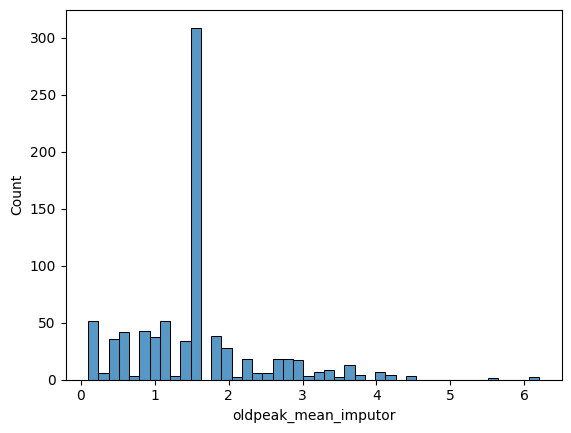

In [455]:
sns.histplot(data = X_train, x = 'oldpeak_mean_imputor')

<Axes: xlabel='oldpeak_mean_imputor', ylabel='Density'>

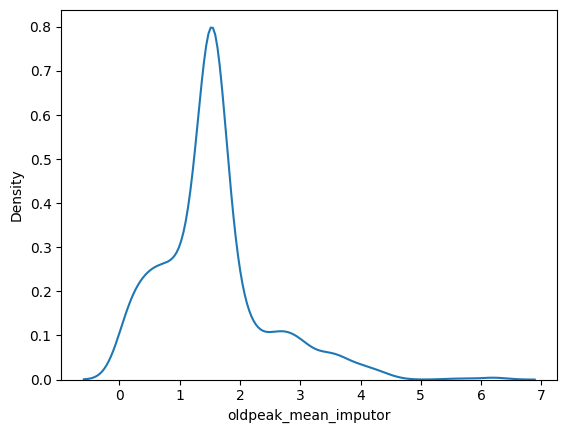

In [456]:
sns.kdeplot(data = X_train, x = 'oldpeak_mean_imputor')

<Axes: xlabel='oldpeak_median_imputor', ylabel='Count'>

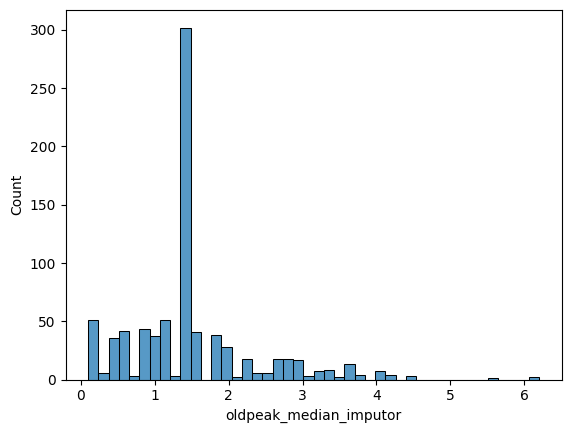

In [457]:
sns.histplot(data = X_train, x = 'oldpeak_median_imputor')

<Axes: xlabel='oldpeak_median_imputor', ylabel='Density'>

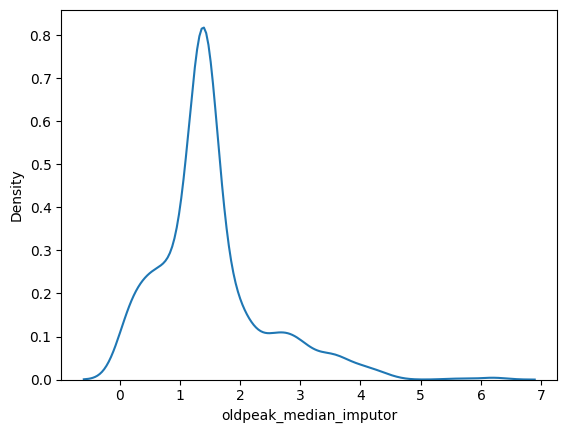

In [458]:
sns.kdeplot(data = X_train, x = 'oldpeak_median_imputor')

In [459]:
X_train['oldpeak'].skew()

np.float64(0.9566336751071198)

In [460]:
X_train['oldpeak'].describe()

,oldpeak
count,552.000000
mean,1.545290
std,1.074087
min,0.100000
25%,0.775000
50%,1.400000
75%,2.100000
max,6.200000


In [461]:
oldpeak_imputer = SimpleImputer(missing_values = np.nan, strategy = 'median')

oldpeak_imputer.fit(X_train[['oldpeak']])

# tranform

X_train['oldpeak'] = oldpeak_imputer.transform(X_train[['oldpeak']])
X_test['oldpeak'] = oldpeak_imputer.transform(X_test[['oldpeak']])

In [462]:
X_train.drop(['oldpeak_mean_imputor', 'oldpeak_median_imputor'], axis = 1, inplace = True)

X_test.drop(['oldpeak_mean_imputor', 'oldpeak_median_imputor'], axis = 1, inplace = True)

In [463]:
X_train.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [464]:
X_test.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


# Outlier detection using IQR

In [465]:
# 'age', 'trestbps', 'chol', 'thalach', 'oldpeak'

age_Q1 = X_train['age'].quantile(0.25)

age_Q3 = X_train['age'].quantile(0.75)

age_IQR = age_Q3 - age_Q1


age_min = age_Q1 - ( 1.5 * age_IQR )

age_max = age_Q3 + ( 1.5 * age_IQR )

print(age_min, age_max)


26.0 82.0


In [466]:
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for col in numerical_cols:
    Q1  = X_train[col].quantile(0.25)
    Q3  = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X_train[(X_train[col] < lower) | (X_train[col] > upper)]
    print(f"{col:10s} | lower: {lower:.2f} | upper: {upper:.2f} | outliers found: {len(outliers)}")

age        | lower: 26.00 | upper: 82.00 | outliers found: 0
trestbps   | lower: 90.00 | upper: 170.00 | outliers found: 25
chol       | lower: 116.50 | upper: 368.50 | outliers found: 10
thalach    | lower: 80.62 | upper: 217.62 | outliers found: 3
oldpeak    | lower: 0.02 | upper: 2.63 | outliers found: 89


In [467]:
X_train.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


# One Hot Encoding

In [468]:
# sex, cp, fbs, restecg, exang, slope, ca, thal

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'ohe', OneHotEncoder(sparse_output=False,drop='first'), ['restecg'] ),

        ('ordinal', OrdinalEncoder(categories=[
                            [0, 1, 2, 3],        # cp
                            [0, 1, 2],           # slope
                            [0, 1, 2, 3, 4],     # ca
                            [0, 1, 2, 3],        # thal
                        ],
                    ), ['cp', 'slope', 'ca', 'thal'])
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(X_train)

X_train = encoder_scaler.transform(X_train)

X_test = encoder_scaler.transform(X_test)


In [469]:
X_train

,restecg_2.0,cp,slope,ca,thal,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak
835,0.0,2.0,2.0,3.0,2.0,49,1.0,118,149,1.0,126,1.0,0.8
137,0.0,2.0,2.0,1.0,2.0,64,1.0,180,325,1.0,154,1.0,1.4
534,0.0,2.0,2.0,1.0,2.0,54,1.0,108,267,1.0,167,1.0,1.4
495,0.0,2.0,1.0,1.0,3.0,59,1.0,135,234,1.0,161,1.0,0.5
244,0.0,2.0,1.0,1.0,2.0,51,1.0,125,245,1.0,166,1.0,2.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,0.0,2.0,1.0,1.0,2.0,41,1.0,130,214,1.0,168,1.0,2.0
71,0.0,2.0,2.0,1.0,3.0,61,1.0,140,207,1.0,138,1.0,1.9
106,0.0,2.0,2.0,1.0,3.0,51,1.0,140,299,1.0,173,1.0,1.6
270,0.0,2.0,2.0,1.0,3.0,43,1.0,110,211,1.0,161,1.0,1.4


In [470]:
print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)

X_train shape: (820, 13)
X_test  shape: (205, 13)


# Final Version

In [471]:
X_train

,restecg_2.0,cp,slope,ca,thal,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak
835,0.0,2.0,2.0,3.0,2.0,49,1.0,118,149,1.0,126,1.0,0.8
137,0.0,2.0,2.0,1.0,2.0,64,1.0,180,325,1.0,154,1.0,1.4
534,0.0,2.0,2.0,1.0,2.0,54,1.0,108,267,1.0,167,1.0,1.4
495,0.0,2.0,1.0,1.0,3.0,59,1.0,135,234,1.0,161,1.0,0.5
244,0.0,2.0,1.0,1.0,2.0,51,1.0,125,245,1.0,166,1.0,2.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,0.0,2.0,1.0,1.0,2.0,41,1.0,130,214,1.0,168,1.0,2.0
71,0.0,2.0,2.0,1.0,3.0,61,1.0,140,207,1.0,138,1.0,1.9
106,0.0,2.0,2.0,1.0,3.0,51,1.0,140,299,1.0,173,1.0,1.6
270,0.0,2.0,2.0,1.0,3.0,43,1.0,110,211,1.0,161,1.0,1.4


In [472]:
X_test

,restecg_2.0,cp,slope,ca,thal,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak
527,0.0,2.0,2.0,1.0,2.0,62,1.0,124,209,1.0,163,1.0,1.4
359,0.0,2.0,2.0,1.0,2.0,53,1.0,128,216,1.0,115,1.0,1.4
447,0.0,2.0,1.0,1.0,3.0,55,1.0,160,289,1.0,145,1.0,0.8
31,0.0,1.0,2.0,1.0,2.0,50,1.0,120,244,1.0,162,1.0,1.1
621,0.0,2.0,2.0,2.0,3.0,48,1.0,130,256,1.0,150,1.0,1.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,0.0,2.0,2.0,1.0,3.0,68,1.0,118,277,1.0,151,1.0,1.0
796,0.0,1.0,1.0,1.0,1.0,41,1.0,135,203,1.0,132,1.0,1.4
644,0.0,2.0,2.0,1.0,2.0,44,1.0,120,226,1.0,169,1.0,1.4
404,0.0,2.0,2.0,1.0,3.0,61,1.0,140,207,1.0,138,1.0,1.9


## 6. Diabetes Dataset – Compare Encoding Techniques

### Dataset
Pima Indians Diabetes Dataset from Kaggle.

https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database?utm_source=chatgpt.com

---

### Tasks

**1. Create a categorical feature from BMI:**
- Underweight (BMI < 18.5)
- Normal (18.5 ≤ BMI < 25)
- Overweight (25 ≤ BMI < 30)
- Obese (BMI ≥ 30)

**2. Apply all three encoding techniques on the new BMI category feature:**
- Label Encoding
- Ordinal Encoding
- One Hot Encoding

**3. Write a short conclusion on which encoding is best for this feature.**

In [473]:
df = pd.read_csv('diabetes.csv')

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [474]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [475]:
df['BMI'].describe()

,BMI
count,768.000000
mean,31.992578
std,7.884160
min,0.000000
25%,27.300000
50%,32.000000
75%,36.600000
max,67.100000


In [476]:
def categorize_bmi(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif 18.5 <= bmi < 25:
        return 'Normal'
    elif 25 <= bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'


df['BMI_category'] = df['BMI'].apply(categorize_bmi)

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_category
0,6,148,72,35,0,33.6,0.627,50,1,Obese
1,1,85,66,29,0,26.6,0.351,31,0,Overweight
2,8,183,64,0,0,23.3,0.672,32,1,Normal
3,1,89,66,23,94,28.1,0.167,21,0,Overweight
4,0,137,40,35,168,43.1,2.288,33,1,Obese
...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,Obese
764,2,122,70,27,0,36.8,0.340,27,0,Obese
765,5,121,72,23,112,26.2,0.245,30,0,Overweight
766,1,126,60,0,0,30.1,0.349,47,1,Obese


<Axes: xlabel='BMI_category', ylabel='count'>

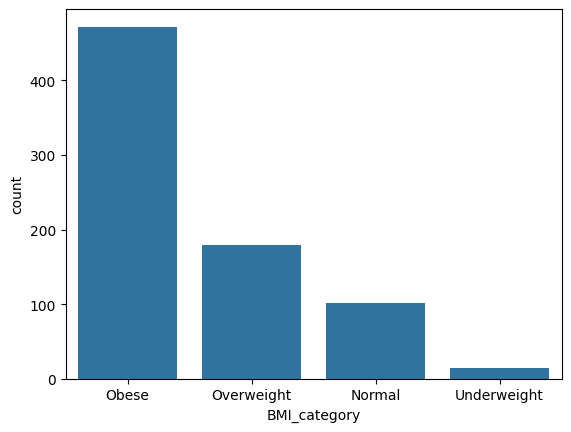

In [477]:
sns.countplot(data = df, x = 'BMI_category')

In [478]:
# Label Encoder

le = LabelEncoder()

le.fit(df['BMI_category'])

df['BMI_label_encoded'] = le.transform(df['BMI_category'])

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_category,BMI_label_encoded
0,6,148,72,35,0,33.6,0.627,50,1,Obese,1
1,1,85,66,29,0,26.6,0.351,31,0,Overweight,2
2,8,183,64,0,0,23.3,0.672,32,1,Normal,0
3,1,89,66,23,94,28.1,0.167,21,0,Overweight,2
4,0,137,40,35,168,43.1,2.288,33,1,Obese,1
...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,Obese,1
764,2,122,70,27,0,36.8,0.340,27,0,Obese,1
765,5,121,72,23,112,26.2,0.245,30,0,Overweight,2
766,1,126,60,0,0,30.1,0.349,47,1,Obese,1


In [479]:
# Ordinal Encoding

bmi_encoder = OrdinalEncoder( categories = [['Underweight', 'Normal', 'Overweight', 'Obese']] )

bmi_encoder.fit(df[['BMI_category']])

# transform

df['encoded_BMI'] = bmi_encoder.transform(df[['BMI_category']]).ravel()

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_category,BMI_label_encoded,encoded_BMI
0,6,148,72,35,0,33.6,0.627,50,1,Obese,1,3.0
1,1,85,66,29,0,26.6,0.351,31,0,Overweight,2,2.0
2,8,183,64,0,0,23.3,0.672,32,1,Normal,0,1.0
3,1,89,66,23,94,28.1,0.167,21,0,Overweight,2,2.0
4,0,137,40,35,168,43.1,2.288,33,1,Obese,1,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,Obese,1,3.0
764,2,122,70,27,0,36.8,0.340,27,0,Obese,1,3.0
765,5,121,72,23,112,26.2,0.245,30,0,Overweight,2,2.0
766,1,126,60,0,0,30.1,0.349,47,1,Obese,1,3.0


In [480]:
# One Hot Encoding

bmi_ohe = OneHotEncoder(sparse_output = False).set_output(transform = 'pandas')

bmi_ohe.fit(df[['BMI_category']])

# transform

encoded_df = bmi_ohe.transform(df[['BMI_category']])

df = pd.concat([df, encoded_df], axis = 1)

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_category,BMI_label_encoded,encoded_BMI,BMI_category_Normal,BMI_category_Obese,BMI_category_Overweight,BMI_category_Underweight
0,6,148,72,35,0,33.6,0.627,50,1,Obese,1,3.0,0.0,1.0,0.0,0.0
1,1,85,66,29,0,26.6,0.351,31,0,Overweight,2,2.0,0.0,0.0,1.0,0.0
2,8,183,64,0,0,23.3,0.672,32,1,Normal,0,1.0,1.0,0.0,0.0,0.0
3,1,89,66,23,94,28.1,0.167,21,0,Overweight,2,2.0,0.0,0.0,1.0,0.0
4,0,137,40,35,168,43.1,2.288,33,1,Obese,1,3.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,Obese,1,3.0,0.0,1.0,0.0,0.0
764,2,122,70,27,0,36.8,0.340,27,0,Obese,1,3.0,0.0,1.0,0.0,0.0
765,5,121,72,23,112,26.2,0.245,30,0,Overweight,2,2.0,0.0,0.0,1.0,0.0
766,1,126,60,0,0,30.1,0.349,47,1,Obese,1,3.0,0.0,1.0,0.0,0.0


## Conclusion – Which Encoding is Best for BMI Category?

BMI_category has a clear natural order:
Underweight < Normal < Overweight < Obese

| Technique | Result | Suitable? |
|---|---|---|
| Label Encoding | Assigns arbitrary codes (Obese=0, Normal=2) | ❌ No — order not guaranteed |
| Ordinal Encoding | Underweight=0, Normal=1, Overweight=2, Obese=3 | ✅ Best choice |
| One Hot Encoding | Creates 4 separate binary columns | ❌ No — destroys the natural order |

**Ordinal Encoding is the best choice** for BMI_category because
it preserves the natural rank of the categories. Label Encoding
assigns codes randomly, and One Hot Encoding treats all categories
as unrelated — both lose the meaningful order that BMI levels carry.

## 6. Hotel Booking Dataset – High Cardinality Encoding

### Dataset
Hotel Booking Demand Dataset from Kaggle.

https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand?utm_source=chatgpt.com
---

### Tasks

**1. Load the dataset.**

**2. Apply the following encodings:**
- One Hot Encoding on `hotel` column
- Label Encoding on booking status column (`reservation_status`)

In [481]:
df = pd.read_csv('hotel_bookings.csv')

df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [482]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [483]:
# One Hot Encoding

hotel_ohe = OneHotEncoder(sparse_output = False).set_output(transform = 'pandas')

hotel_ohe.fit(df[['hotel']])

encoded_df = hotel_ohe.transform(df[['hotel']])

df = pd.concat([df, encoded_df], axis = 1)

df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,hotel_City Hotel,hotel_Resort Hotel
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,0.0,1.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,0.0,1.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,0.0,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,0.0,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06,1.0,0.0
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07,1.0,0.0
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07,1.0,0.0
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07,1.0,0.0


In [484]:
# Label Encoding

le = LabelEncoder()

le.fit(df['reservation_status'])

df['reservation_status_encoded'] = le.transform(df['reservation_status'])

df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,hotel_City Hotel,hotel_Resort Hotel,reservation_status_encoded
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0,Transient,0.00,0,0,Check-Out,2015-07-01,0.0,1.0,1
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0,Transient,0.00,0,0,Check-Out,2015-07-01,0.0,1.0,1
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0,Transient,75.00,0,0,Check-Out,2015-07-02,0.0,1.0,1
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,0,Transient,75.00,0,0,Check-Out,2015-07-02,0.0,1.0,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0,Transient,98.00,0,1,Check-Out,2015-07-03,0.0,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,0,Transient,96.14,0,0,Check-Out,2017-09-06,1.0,0.0,1
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,0,Transient,225.43,0,2,Check-Out,2017-09-07,1.0,0.0,1
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,0,Transient,157.71,0,4,Check-Out,2017-09-07,1.0,0.0,1
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,0,Transient,104.40,0,0,Check-Out,2017-09-07,1.0,0.0,1


<Axes: xlabel='reservation_status_encoded', ylabel='count'>

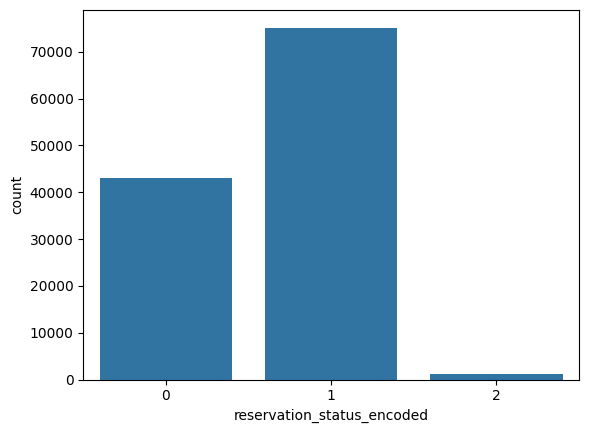

In [485]:
sns.countplot(data = df, x = 'reservation_status_encoded')

## 8. Employee Attrition Dataset – Advanced Encoding Challenge

### Dataset
IBM HR Analytics Employee Attrition Dataset from Kaggle.

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset?utm_source=chatgpt.com

---

### Tasks

**1. Split the dataset into train and test sets.**

**2. Detect all categorical columns automatically.**

**3. Apply the following encodings:**
- Ordinal Encoding for education level
- One Hot Encoding for department
- Label Encoding for target column (`Attrition`)

**4. Handle unseen categories in test data.**

**5. (Optional) Create a reusable preprocessing function.**

**6. Display transformed train and test datasets.**

In [486]:
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [487]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [488]:
X = df.drop('Attrition', axis = 1)

y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [489]:
X_train

display(y_train)

,Attrition
1097,No
727,No
254,No
1175,No
1341,No
...,...
1130,No
1294,No
860,Yes
1459,No


In [490]:
X_test

display(y_test)

,Attrition
1041,No
184,No
1222,Yes
67,No
220,No
...,...
567,No
560,No
945,No
522,No


In [491]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1176 entries, 1097 to 1126
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1176 non-null   int64 
 1   BusinessTravel            1176 non-null   object
 2   DailyRate                 1176 non-null   int64 
 3   Department                1176 non-null   object
 4   DistanceFromHome          1176 non-null   int64 
 5   Education                 1176 non-null   int64 
 6   EducationField            1176 non-null   object
 7   EmployeeCount             1176 non-null   int64 
 8   EmployeeNumber            1176 non-null   int64 
 9   EnvironmentSatisfaction   1176 non-null   int64 
 10  Gender                    1176 non-null   object
 11  HourlyRate                1176 non-null   int64 
 12  JobInvolvement            1176 non-null   int64 
 13  JobLevel                  1176 non-null   int64 
 14  JobRole                   

In [492]:
X_train['YearsWithCurrManager'].unique()

array([ 0,  2,  8, 11,  4,  1,  7, 16,  3, 10, 14,  9, 12, 13,  6,  5, 17,
       15])

In [493]:
# BusinessTravel, Department, Education, EducationField, EmployeeCount, EnvironmentSatisfaction, Gender, JobInvolvement,
# JobLevel, JobRole, JobSatisfaction, MaritalStatus, OverTime,
# PerformanceRating, RelationshipSatisfaction, StockOptionLevel, TrainingTimesLastYear
# WorkLifeBalance

In [494]:
from sklearn.compose import make_column_selector

cat_selector = make_column_selector(dtype_include=['object', 'category'])

cat_cols = cat_selector(df)

print(cat_cols)

['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


<Axes: xlabel='EducationField', ylabel='Count'>

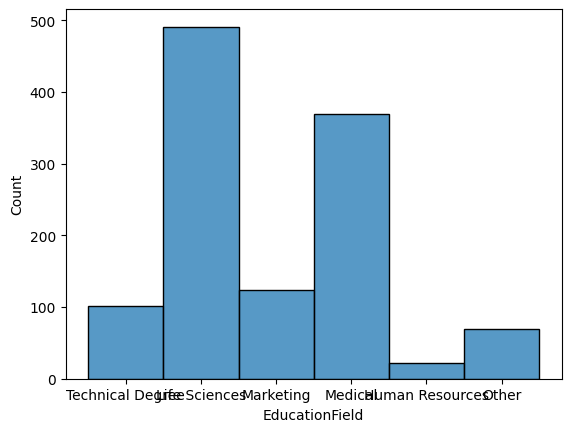

In [495]:
sns.histplot(data = X_train, x = X_train['EducationField'])

In [496]:
X_train['EducationField'].unique()

array(['Technical Degree', 'Life Sciences', 'Marketing', 'Medical',
       'Human Resources', 'Other'], dtype=object)

In [497]:
# Ordinal Encoding on Education Level

educationfield_encoder = OrdinalEncoder(
    categories=[[
        "Human Resources",
        "Life Sciences",
        "Marketing",
        "Medical",
        "Other",
        "Technical Degree"
    ]],
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

educationfield_encoder.fit(X_train[['EducationField']])

X_train['encoded_EducationField'] = educationfield_encoder.transform(X_train[['EducationField']]).ravel()

X_test['encoded_EducationField'] = educationfield_encoder.transform(X_test[['EducationField']]).ravel()

In [498]:
X_train['encoded_EducationField']

,encoded_EducationField
1097,5.0
727,1.0
254,2.0
1175,3.0
1341,1.0
...,...
1130,1.0
1294,1.0
860,1.0
1459,4.0


In [499]:
# One Hot Encoding for department

department_ohe = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
).set_output(transform='pandas')

department_ohe.fit(X_train[['Department']])

encoded_df = department_ohe.transform(X_train[['Department']])

X_train = pd.concat([X_train, encoded_df], axis = 1)

X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1176 entries, 1097 to 1126
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                1176 non-null   int64  
 1   BusinessTravel                     1176 non-null   object 
 2   DailyRate                          1176 non-null   int64  
 3   Department                         1176 non-null   object 
 4   DistanceFromHome                   1176 non-null   int64  
 5   Education                          1176 non-null   int64  
 6   EducationField                     1176 non-null   object 
 7   EmployeeCount                      1176 non-null   int64  
 8   EmployeeNumber                     1176 non-null   int64  
 9   EnvironmentSatisfaction            1176 non-null   int64  
 10  Gender                             1176 non-null   object 
 11  HourlyRate                         1176 non-null   int64  

In [500]:
encoded_df = department_ohe.transform(X_test[['Department']])

X_test = pd.concat([X_test, encoded_df], axis = 1)

X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 294 entries, 1041 to 651
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                294 non-null    int64  
 1   BusinessTravel                     294 non-null    object 
 2   DailyRate                          294 non-null    int64  
 3   Department                         294 non-null    object 
 4   DistanceFromHome                   294 non-null    int64  
 5   Education                          294 non-null    int64  
 6   EducationField                     294 non-null    object 
 7   EmployeeCount                      294 non-null    int64  
 8   EmployeeNumber                     294 non-null    int64  
 9   EnvironmentSatisfaction            294 non-null    int64  
 10  Gender                             294 non-null    object 
 11  HourlyRate                         294 non-null    int64  
 

In [501]:
# Label Encoding for target column

y_train

type(y_train)

pandas.core.series.Series

In [502]:
le = LabelEncoder()

le.fit(y_train)

y_train_array = le.transform(y_train)

y_test_array = le.transform(y_test)

In [503]:
y_train = pd.Series(y_train_array, index = y_train.index, name = y_train.name)

y_test = pd.Series(y_test_array, index = y_test.index, name = y_test.name)

In [504]:
y_train

,Attrition
1097,0
727,0
254,0
1175,0
1341,0
...,...
1130,0
1294,0
860,1
1459,0


In [505]:
y_test

,Attrition
1041,0
184,0
1222,1
67,0
220,0
...,...
567,0
560,0
945,0
522,0


In [506]:
def preprocess_hr_data(df):

    X = df.drop('Attrition', axis=1)
    y = df['Attrition']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )

    # Ordinal Encoding
    educationfield_encoder = OrdinalEncoder(
        categories=[[
            "Human Resources",
            "Life Sciences",
            "Marketing",
            "Medical",
            "Other",
            "Technical Degree"
        ]],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    educationfield_encoder.fit(X_train[['EducationField']])

    X_train['encoded_EducationField'] = (
        educationfield_encoder.transform(
            X_train[['EducationField']]
        ).ravel()
    )

    X_test['encoded_EducationField'] = (
        educationfield_encoder.transform(
            X_test[['EducationField']]
        ).ravel()
    )

    # One Hot Encoding
    department_ohe = OneHotEncoder(
        sparse_output=False,
        handle_unknown='ignore'
    ).set_output(transform='pandas')

    department_ohe.fit(X_train[['Department']])

    train_encoded = department_ohe.transform(
        X_train[['Department']]
    )

    test_encoded = department_ohe.transform(
        X_test[['Department']]
    )

    X_train = pd.concat([X_train, train_encoded], axis=1)
    X_test = pd.concat([X_test, test_encoded], axis=1)

    # Label Encoding
    le = LabelEncoder()

    y_train = pd.Series(
        le.fit_transform(y_train),
        index=y_train.index
    )

    y_test = pd.Series(
        le.transform(y_test),
        index=y_test.index
    )

    return X_train, X_test, y_train, y_test

In [507]:
X_train, X_test, y_train, y_test = preprocess_hr_data(df)

In [508]:
print("Transformed X_train:")
print(X_train.head())

print("\nTransformed X_test:")
print(X_test.head())

Transformed X_train:
      Age BusinessTravel  DailyRate              Department  DistanceFromHome  \
1097   24  Travel_Rarely        350  Research & Development                21   
727    18     Non-Travel        287  Research & Development                 5   
254    29  Travel_Rarely       1247                   Sales                20   
1175   39  Travel_Rarely        492  Research & Development                12   
1341   31  Travel_Rarely        311  Research & Development                20   

      Education    EducationField  EmployeeCount  EmployeeNumber  \
1097          2  Technical Degree              1            1551   
727           2     Life Sciences              1            1012   
254           2         Marketing              1             349   
1175          3           Medical              1            1654   
1341          3     Life Sciences              1            1881   

      EnvironmentSatisfaction  ... TrainingTimesLastYear  WorkLifeBalance  \
1097  

In [509]:
print("\nEncoded y_train:")
print(y_train.head())

print("\nEncoded y_test:")
print(y_test.head())


Encoded y_train:
1097    0
727     0
254     0
1175    0
1341    0
dtype: int64

Encoded y_test:
1041    0
184     0
1222    1
67      0
220     0
dtype: int64
